In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import wntr
import wntr.graphics as wntr_graphics
import networkx as nx
import os

from utils import (
    leak_info, calcular_residuo, normalizar_residuo, taxa_exceedance, nodes_distance, load_scenario
)

# Loading files

✅ Mapa da rede carregado! 
(32 nós e 34 canos).


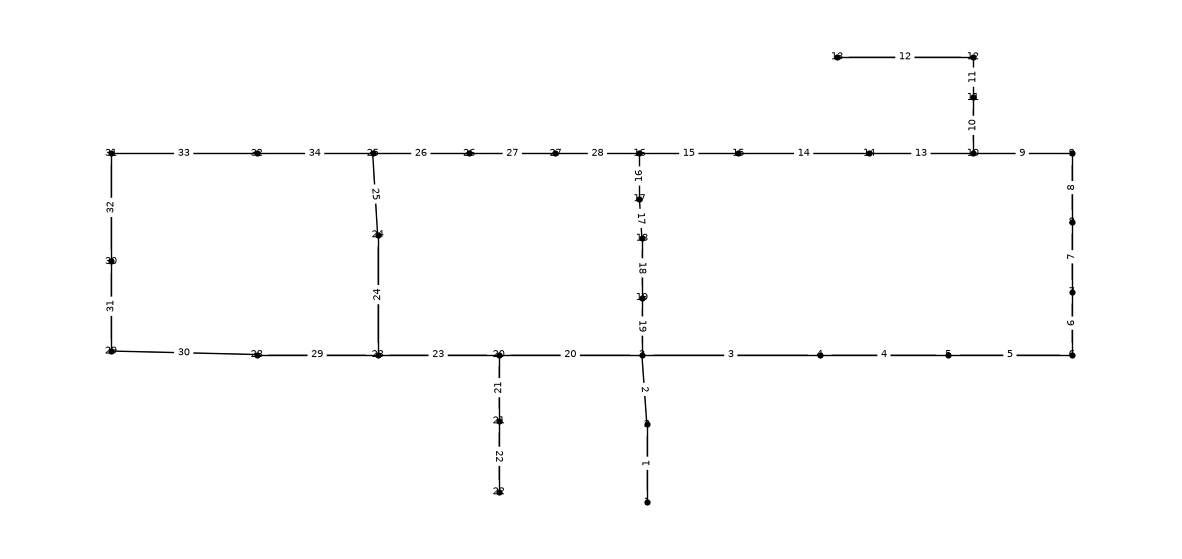

In [14]:
# definir scenario
pasta_cenario = r"C:\Users\Mirella Fontinelle\Leakage Research\data\object\train\Scenario-25"

# definir paths para o arquivo .inp e para a pasta de pressões
arquivo_inp = os.path.join(pasta_cenario, 'hanoi_cmh_scenario-25.inp')

# carregar e validar a topologia física da rede Hanoi
if os.path.exists(arquivo_inp):
    wn = wntr.network.WaterNetworkModel(arquivo_inp)
    print(f"✅ Mapa da rede carregado! \n({wn.num_nodes} nós e {wn.num_links} canos).")

    fig, ax = plt.subplots(figsize=(15, 7))

    wntr_graphics.plot_network (wn,
                                ax=ax,
                                node_size=20,
                                link_width=1,
                                node_labels=True,
                                link_labels=True)
else:
    print(f"❌ Erro: Arquivo .inp em: {arquivo_inp} não encontrado")

# Experimentos hard-coding - cenário 25

In [15]:
# declara pasta_pressures
pasta_pressures = os.path.join(pasta_cenario, 'pressures')

# ir em 'Pressures' e ler o arquivo do nó escolhido
if os.path.isdir(pasta_pressures):
    # lista todos os arquivos de nós na pasta 'Pressures'
    arquivos_nos = os.listdir(pasta_pressures)
    print(f"✅ Pasta 'pressures' encontrada com {len(arquivos_nos)} arquivos de nós.")
    
    # pega o primeiro arquivo de nó da lista para testar o gráfico
    nome_arquivo_no = "Node_31.csv"
    caminho_arquivo_no = os.path.join(pasta_pressures, nome_arquivo_no)
    
    # lê o arquivo de texto como .csv 
    df_no = pd.read_csv(caminho_arquivo_no)
    print(f"✅ {nome_arquivo_no} encontrado")
    print(df_no.head())
else:
    print(f"❌ Erro: O caminho {pasta_pressures} não é uma pasta válida.")

✅ Pasta 'pressures' encontrada com 32 arquivos de nós.
✅ Node_31.csv encontrado
   Index   Value
0      1  67.890
1      2  68.316
2      3  68.612
3      4  68.839
4      5  68.994


## Leakage observatory
Scenario 25

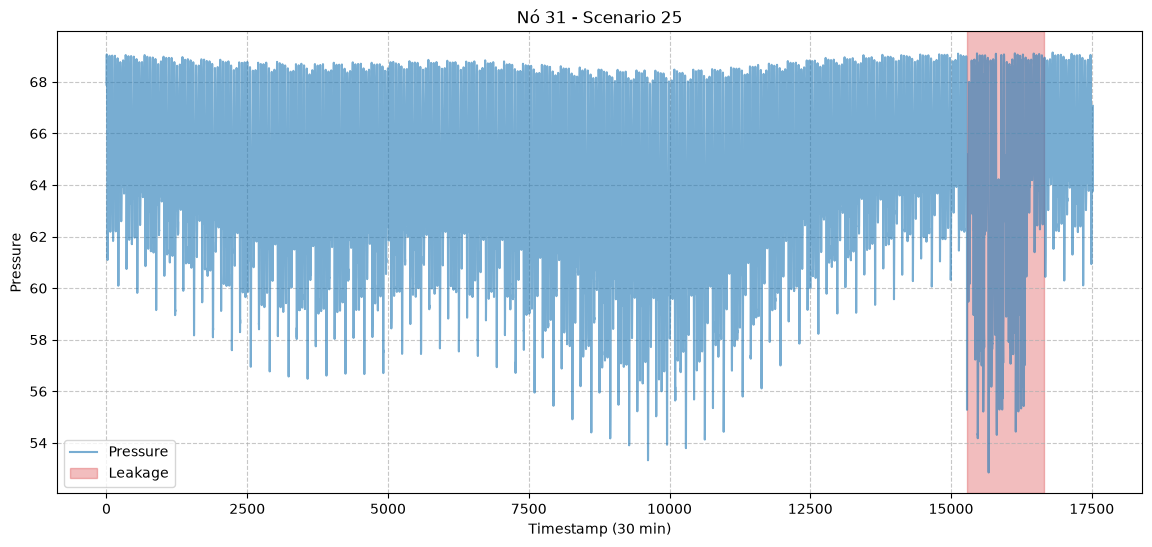

In [16]:
# declara pasta leaks
pasta_leaks = os.path.join(pasta_cenario, 'Leaks')

# ir em 'Leaks' e ler o arquivo do vazamento escolhido
if os.path.isdir(pasta_leaks):

    # pega info do único vazamento
    nome_arquivo_leak = "Leak_31_info.csv"
    caminho_arquivo_leak = os.path.join(pasta_leaks, nome_arquivo_leak)

    # lê arquivo csv
    df_leak_info = pd.read_csv(caminho_arquivo_leak)

    # formatação
    df_leak_info.columns = df_leak_info.columns.str.strip()
    df_leak_info['Description'] = df_leak_info['Description'].str.strip() 

    # index
    df_leak_info.set_index('Description', inplace=True)

    # extract
    start = int(df_leak_info.loc['Leak Start', 'Value'])
    end = int(df_leak_info.loc['Leak End', 'Value'])
    leak_node = int(df_leak_info.loc['Leak Node', 'Value'])

plt.figure(figsize=(14, 6))
plt.plot(df_no['Value'], color='tab:blue', alpha=0.6, label='Pressure')

plt.axvspan(start, end, color='tab:red', alpha=0.3, label='Leakage')
plt.title(f"Nó 31 - Scenario 25")
plt.xlabel("Timestamp (30 min)")
plt.ylabel("Pressure")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

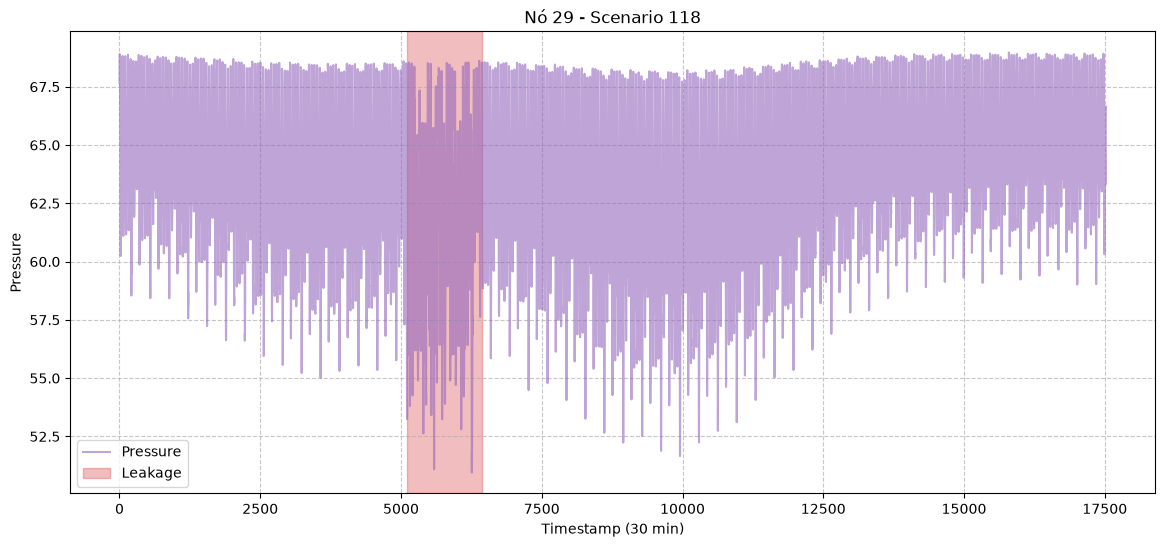

In [17]:
cenario_118_no_29 = r"C:\Users\Mirella Fontinelle\Leakage Research\data\object\train\Scenario-118\Pressures\Node_29.csv"
df_no_29 = pd.read_csv(cenario_118_no_29)

info_118_29 = r"C:\Users\Mirella Fontinelle\Leakage Research\data\object\train\Scenario-118\Leaks\Leak_18_info.csv"
df_info_29 = pd.read_csv(info_118_29)

df_info_29.columns = df_info_29.columns.str.strip()
df_info_29['Description'] = df_info_29['Description'].str.strip()

df_info_29.set_index('Description', inplace=True)

start_29 = int(df_info_29.loc['Leak Start', 'Value'])
end_29 = int(df_info_29.loc['Leak End', 'Value'])
leak_node = int(df_info_29.loc['Leak Node', 'Value'])

plt.figure(figsize=(14, 6))
plt.plot(df_no_29['Value'], color='tab:purple', alpha=0.6, label='Pressure')

plt.axvspan(start_29, end_29, color='tab:red', alpha=0.3, label='Leakage')
plt.title(f"Nó 29 - Scenario 118")
plt.xlabel("Timestamp (30 min)")
plt.ylabel("Pressure")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

## No leakage observatory
Scenario 146

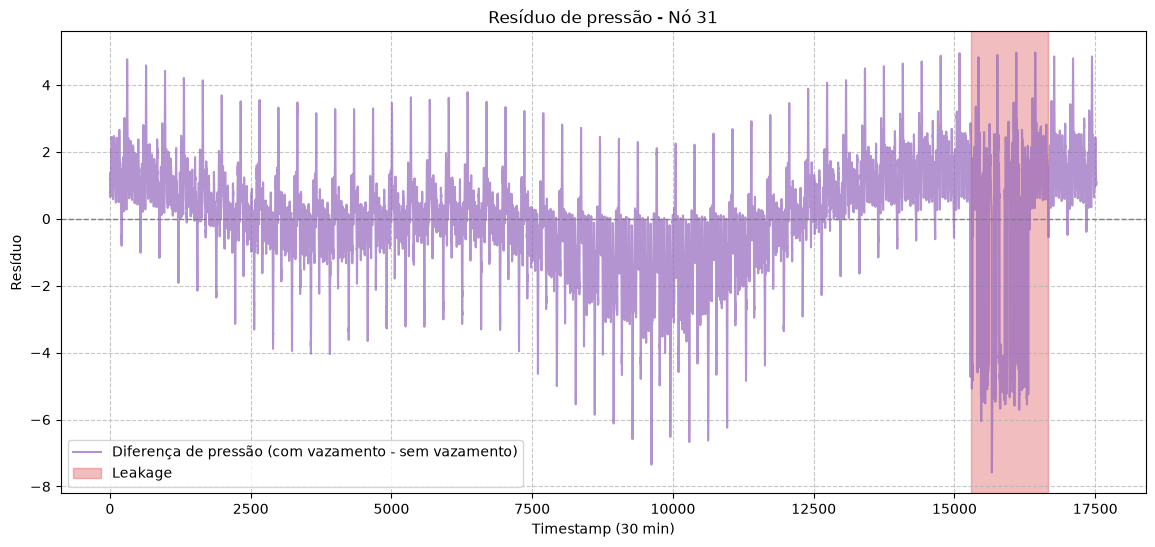

In [18]:
pasta_baseline = r"C:\Users\Mirella Fontinelle\Leakage Research\data\object\train\Scenario-146"
pasta_baseline_pressures = os.path.join(pasta_baseline, 'Pressures')
df_baseline = pd.read_csv(os.path.join(pasta_baseline_pressures, "Node_31.csv"))

# perfil médio por hora do dia -> sem leakage
df_baseline['hour'] = df_baseline.index % 48
esperado_baseline = df_baseline.groupby('hour')['Value'].mean()

# perfil médio por hora do dia -> com leakage
df_no['hour'] = df_no.index % 48
df_no['esperado'] = df_no['hour'].map(esperado_baseline)
df_no['error'] = df_no['Value'] - df_no['esperado']

plt.figure(figsize=(14, 6))
plt.plot(df_no['error'], color='tab:purple', alpha=0.7, label='Diferença de pressão (com vazamento - sem vazamento)')
plt.axvspan(start, end, color='tab:red', alpha=0.3, label='Leakage')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title ("Resíduo de pressão - Nó 31")
plt.xlabel("Timestamp (30 min)")
plt.ylabel("Resíduo")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()



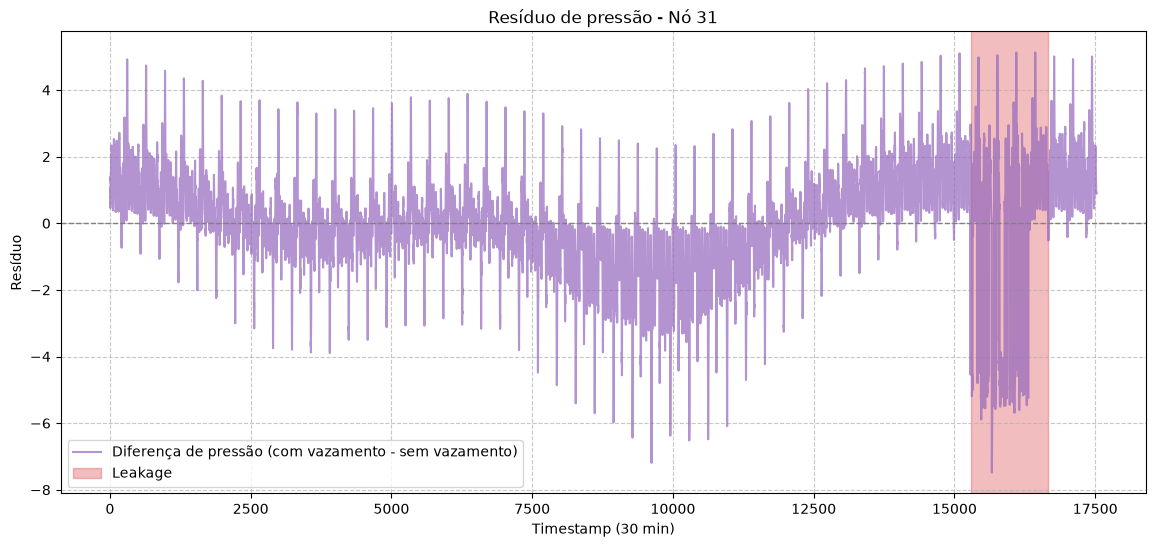

In [19]:
# usa a parte do scenario 25 antes do vazamento como baseline
df_no['hour'] = df_no.index % 48
baseline_local = df_no[df_no.index < start]
esperado_local = baseline_local.groupby('hour')['Value'].mean()

df_no['esperado_local'] = df_no['hour'].map(esperado_local)
df_no['error_local'] = df_no['Value'] - df_no['esperado_local']

plt.figure(figsize=(14, 6))
plt.plot(df_no['error_local'], color='tab:purple', alpha=0.7, label='Diferença de pressão (com vazamento - sem vazamento)')
plt.axvspan(start, end, color='tab:red', alpha=0.3, label='Leakage')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title ("Resíduo de pressão - Nó 31")
plt.xlabel("Timestamp (30 min)")
plt.ylabel("Resíduo")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Média móvel por sazonalizade

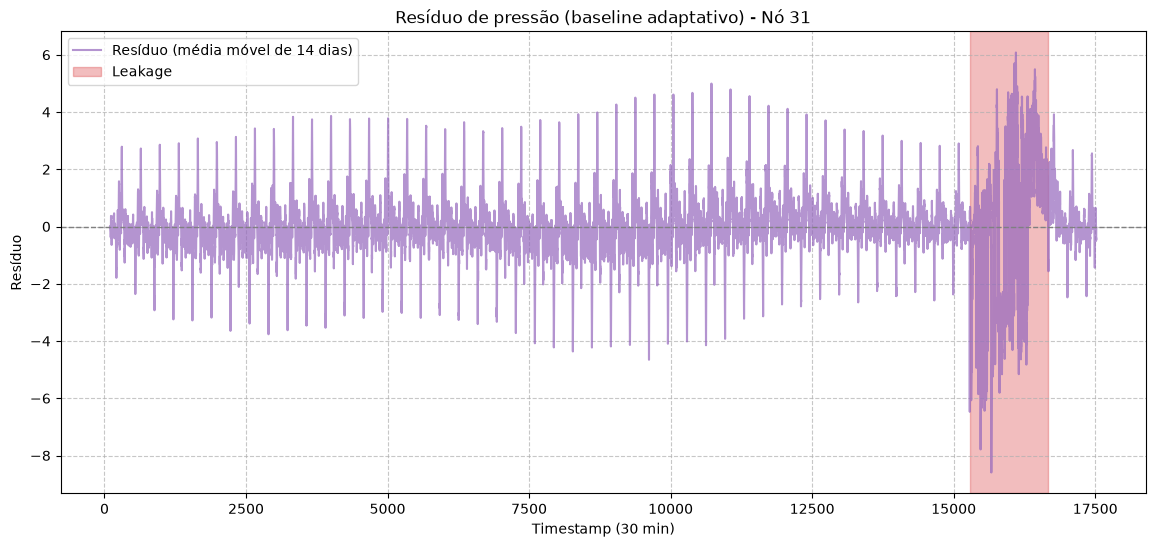

In [20]:
df_no['hour'] = df_no.index % 48
janela_dias = 14 # dias para serem considerados

# série vazia que guarda valor esperado para cada timestamp
esperado_movel = pd.Series(index=df_no.index, dtype=float) 
for h in range(48):
    idx_h = df_no.index[df_no['hour'] == h]
    serie_h = df_no.loc[idx_h, 'Value']
    media_movel_h = serie_h.rolling(window=janela_dias, min_periods=3).mean()
    esperado_movel.loc[idx_h] = media_movel_h.values

df_no['esperado_movel'] = esperado_movel
df_no['error_movel'] = df_no['Value'] - df_no['esperado_movel']

plt.figure(figsize=(14, 6))
plt.plot(df_no['error_movel'], color='tab:purple', alpha=0.7, label='Resíduo (média móvel de 14 dias)')
plt.axvspan(start, end, color='tab:red', alpha=0.3, label='Leakage')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title("Resíduo de pressão (baseline adaptativo) - Nó 31")
plt.xlabel("Timestamp (30 min)")
plt.ylabel("Resíduo")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Refactor e generalização

In [ ]:
# definir cenários e nós estudados
scenarios = {
    25: {
        "path": r"C:\Users\Mirella Fontinelle\Leakage Research\data\object\train\Scenario-25",
        "inp": r"C:\Users\Mirella Fontinelle\Leakage Research\data\object\train\Scenario-25\Hanoi_CMH_Scenario-25.inp",
        "leak": 31,
        "neigh": 30,
        "far": 9
    },
    118: {
        "path": r"C:\Users\Mirella Fontinelle\Leakage Research\data\object\train\Scenario-118",
        "inp": r"C:\Users\Mirella Fontinelle\Leakage Research\data\object\train\Scenario-25\Hanoi_CMH_Scenario-25.inp",
        "leak": 18,
        "neigh": 19,
        "far": 31
    }
}

# roda pra todos os cenários e guarda tudo
resultados_cenario = {}
nodes_cenario = {}
janelas_cenario = {}
linhas_tb = []

for scenario, item in scenarios.items():
    resultados, nodes, start, end, peak, linhas = load_scenario(scenario, item, 14, 3)

    resultados_cenario[scenario] = resultados
    nodes_cenario[scenario] = nodes
    janelas_cenario[scenario] = (start, end)
    linhas_tb.extend(linhas)

In [22]:
tb_resultados = pd.DataFrame(linhas_tb)
print(tb_resultados)

   Cenário            Nó  % |z|>3 dentro do leak  % |z|>3 fora do leak
0       25  Nó Vazamento                   45.93                  2.82
1       25    Nó Vizinho                   44.33                  2.82
2       25   Nó Distante                    1.45                  2.86
3      118  Nó Vazamento                   94.65                  4.53
4      118    Nó Vizinho                   83.04                  3.84
5      118   Nó Distante                   22.83                  3.07


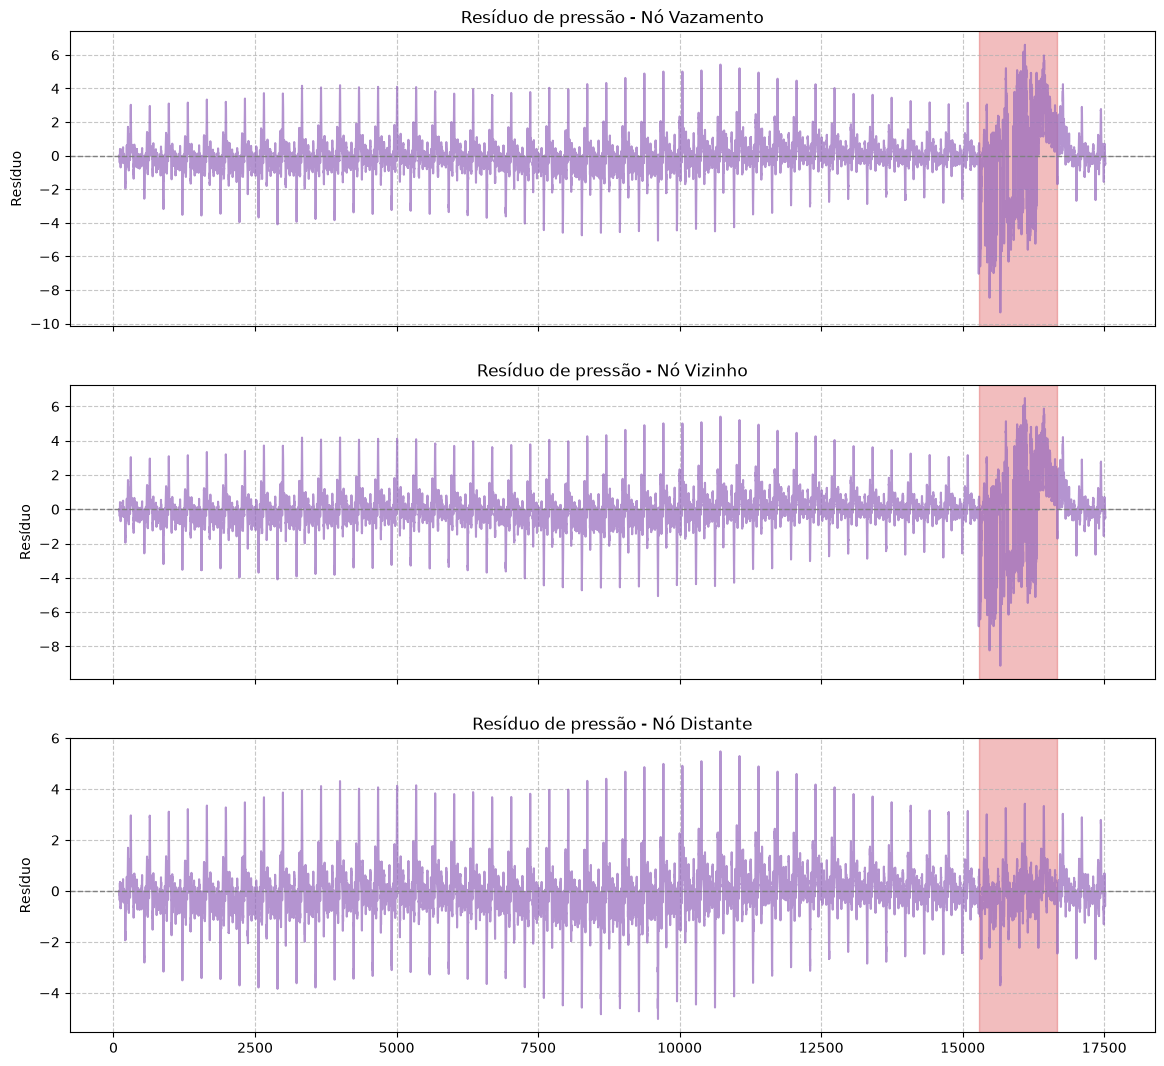

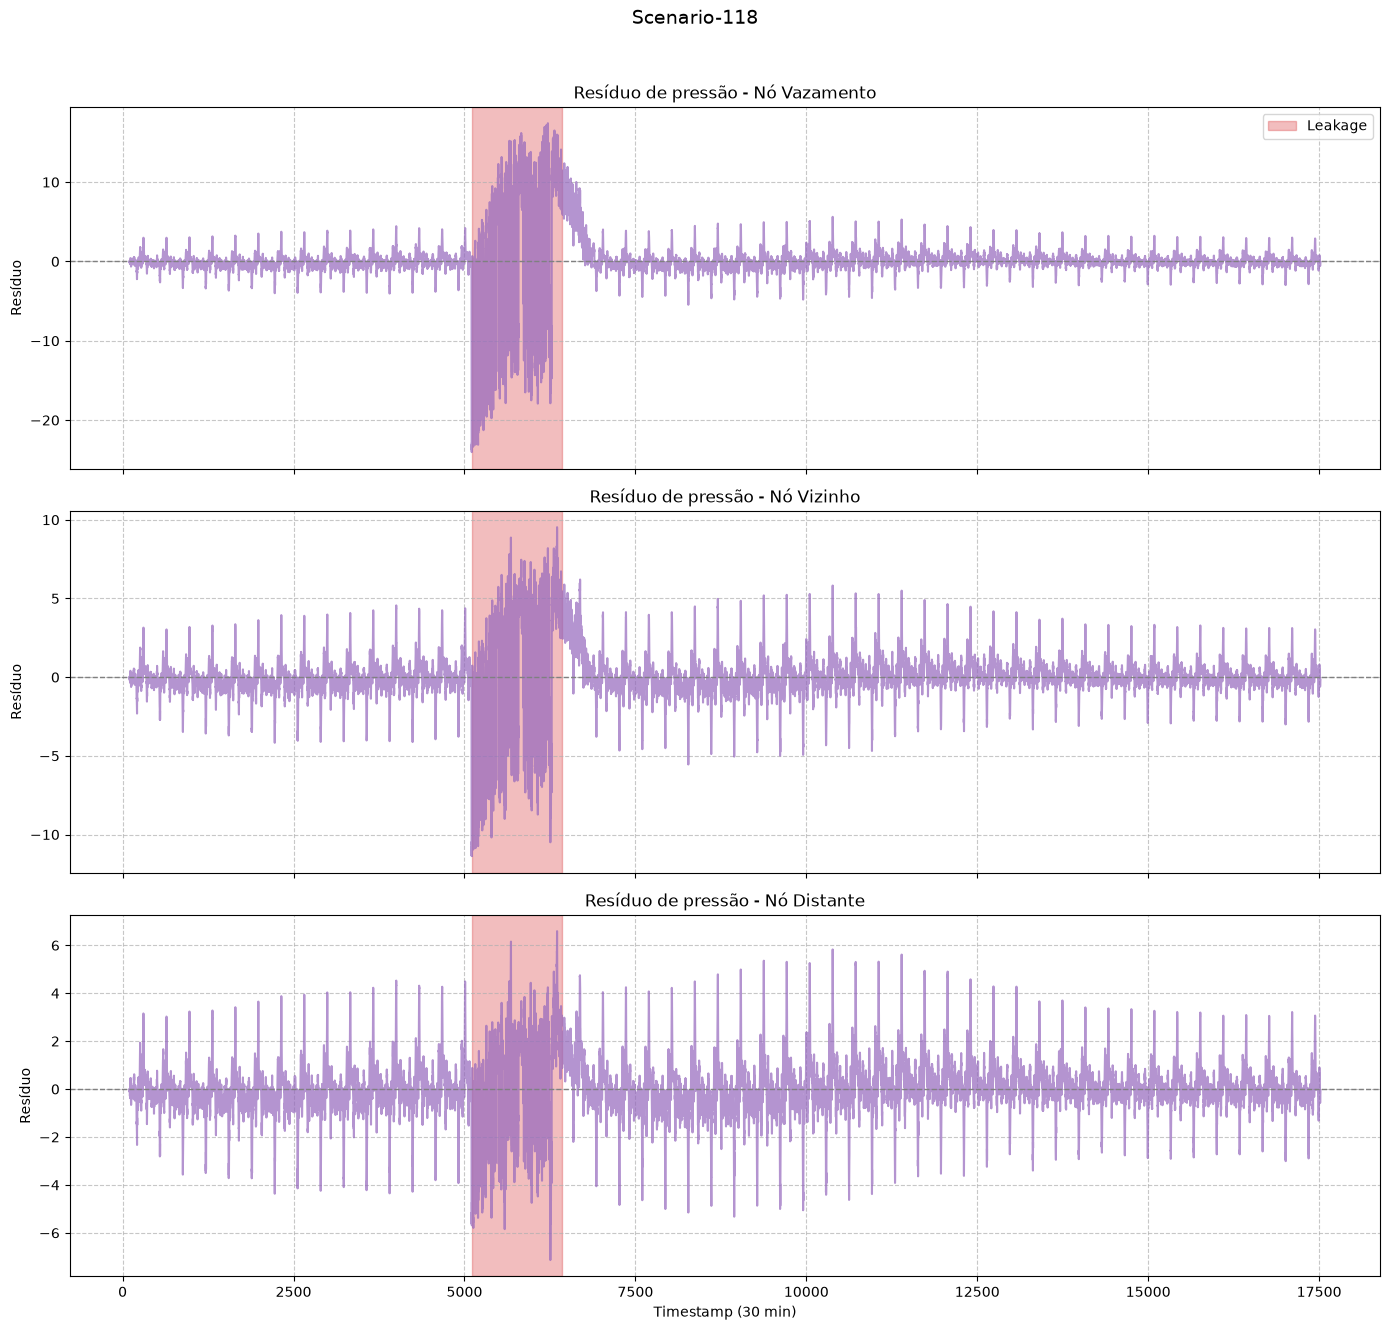

In [23]:
for scenario, item in scenarios.items():
    resultados = resultados_cenario[scenario]
    nodes = nodes_cenario[scenario]
    start, end = janelas_cenario[scenario]

    fig, axes = plt.subplots(len(nodes), 1, figsize=(14, 13), sharex=True)

    for ax, (node, label) in zip(axes, nodes.items()):
        df_res = resultados[node]
        ax.plot(df_res['error_normalizado'], color='tab:purple', alpha=0.7)
        ax.axvspan(start, end, color='tab:red', alpha=0.3, label='Leakage')
        ax.axhline(0, color='gray', linestyle='--', linewidth=1)
        ax.set_title(f"Resíduo de pressão - {label}")
        ax.set_ylabel("Resíduo")
        ax.grid(True, linestyle='--', alpha=0.7)

axes[-1].set_xlabel("Timestamp (30 min)")
axes[0].legend()
fig.suptitle(f"Scenario-{scenario}", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Todos os nós

In [24]:
# função que monta dict com TODOS os nós de uma rede rotulados pela distância até o nó de vazamento
def nodes_distance(item): 
    wn = wntr.network.WaterNetworkModel(item['inp'])
    G = wn.to_graph().to_undirected()

    nodes = {}
    for node in wn.junction_name_list: 
        try: 
            distance = nx.shortest_path_length(G, source=str(item['leak']), target=str(node))
        except nx.NetworkXNoPath:
            print("Sem caminho até:", node)
            continue
        nodes[node] = f'{node}: Distância {distance}'
        
    return nodes

In [25]:
linhas_gen = []
for scenario, item in scenarios.items():
    _, _, _, _, _, linhas = load_scenario(scenario, item, 14, 3, load_nodes=nodes_distance)
    linhas_gen.extend(linhas)

tabela_gen = pd.DataFrame(linhas_gen)
pd.set_option('display.max_rows', None)
display(tabela_gen)

,Cenário,Nó,% |z|>3 dentro do leak,% |z|>3 fora do leak
0,25,10: Distância 8,1.45,2.86
1,25,11: Distância 9,1.38,2.84
2,25,12: Distância 10,1.38,2.84
3,25,13: Distância 11,1.24,2.80
4,25,14: Distância 7,1.60,2.85
5,25,15: Distância 6,1.82,2.84
6,25,16: Distância 5,1.96,2.84
7,25,17: Distância 6,1.53,2.78
8,25,18: Distância 7,1.74,2.84
9,25,19: Distância 7,1.82,2.84


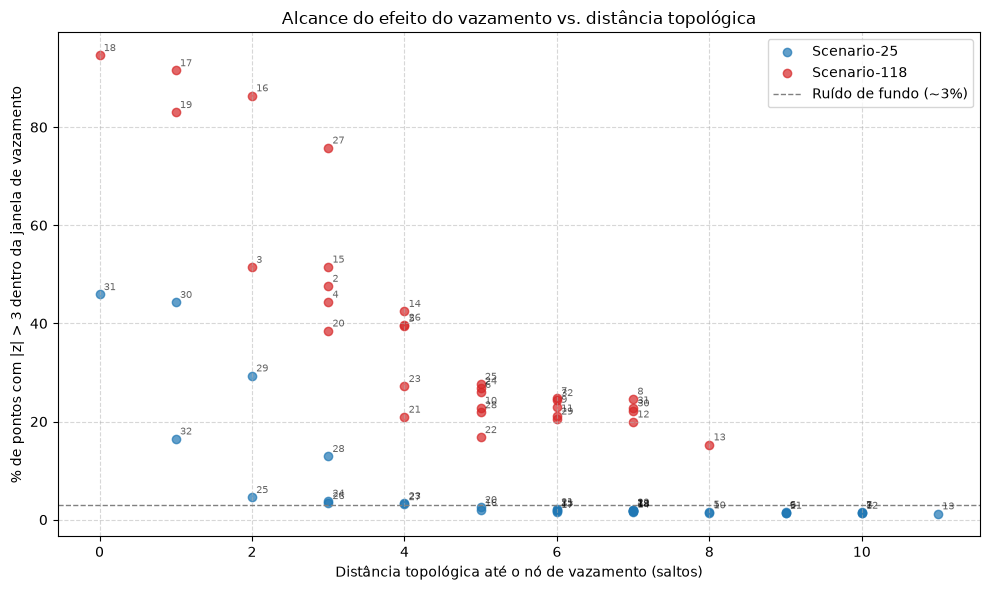

In [26]:
# separa distância e número do nó da coluna de texto
tabela_gen['Distância'] = tabela_gen['Nó'].str.extract(r'Distância (\d+)').astype(int)
tabela_gen['Nó_numero'] = tabela_gen['Nó'].str.extract(r'^(\d+):').astype(int)

fig, ax = plt.subplots(figsize=(10, 6))

cores = {25: 'tab:blue', 118: 'tab:red'}

for cenario, cor in cores.items():
    subset = tabela_gen[tabela_gen['Cenário'] == cenario]
    ax.scatter(subset['Distância'], subset['% |z|>3 dentro do leak'],
                color=cor, alpha=0.7, label=f'Scenario-{cenario}')

    # anota o número do nó em cada ponto, pra identificar outliers depois
    for _, row in subset.iterrows():
        ax.annotate(str(row['Nó_numero']),
                    (row['Distância'], row['% |z|>3 dentro do leak']),
                    fontsize=7, alpha=0.6,
                    xytext=(3, 3), textcoords='offset points')

ax.axhline(3, color='gray', linestyle='--', linewidth=1, label='Ruído de fundo (~3%)')
ax.set_xlabel('Distância topológica até o nó de vazamento (saltos)')
ax.set_ylabel('% de pontos com |z| > 3 dentro da janela de vazamento')
ax.set_title('Alcance do efeito do vazamento vs. distância topológica')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()